# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Gonzales, Naeumi
- _Student No._: 2024-11022
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Synthetic Data Interpolation](sine_interp.png)

**Figure 1. Synthetic data interpolation.** Comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations

![Real-world data reconstruction](dowjones.png)

**Figure 2. Real-world data reconstruction.** Four reconstruction plots of the Dow Jones time-series dataset for sampling levels of 50%, 30%, 10%, and 5%

### Report discussion

**Interpolator comparison:** Higher-order methods (quadratic and cubic) reconstruct smooth, continuous functions like sine waves best, fitting the original curve almost perfectly. The nearest method yields a discontinuous, stepped approximation, whereas linear interpolation produces jagged and sharp segments.

**Sampling-level comparison:** For the Dow Jones time series, higher sampling rates (30%–50%) maintain high accuracy across all methods. At sparse levels (5%–10%), however, quadratic and cubic methods fail by wildly overshooting and oscillating between distant points. While linear interpolation avoids these artificial spikes, it smooths out fine details. Crucially, none of the methods can extrapolate beyond the sample's end boundary points.

### Other comments
- none

---
## Section 2: Code

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

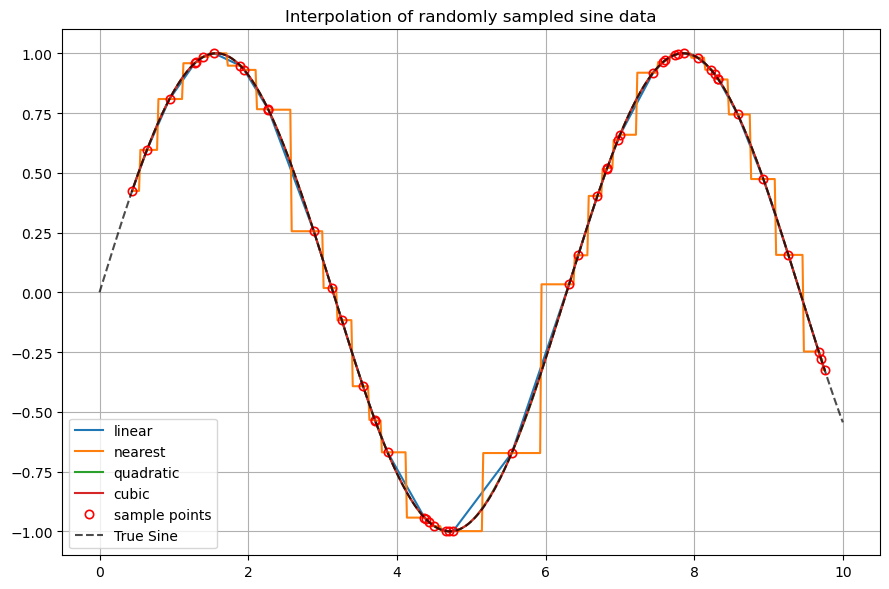

In [27]:
# Generate smooth sine wave for reference
true_x = np.linspace(0, 10, 500)
true_y = np.sin(true_x)

# Sample 50 random points along the sine curve to act as sparse data
sample_x = np.sort(rng.uniform(0, 10, 50))
sample_y = np.sin(sample_x)

# Dense grid across the sample range to evaluate continuous interpolations
x_interp = np.linspace(sample_x[0], sample_x[-1], 500)

plt.figure(figsize=(9, 6))

# Compare different interpolation methods
for method in ['linear', 'nearest', 'quadratic', 'cubic']:
    f = interpolate.interp1d(sample_x, sample_y, kind=method)
    plt.plot(x_interp, f(x_interp), label=method)

# Plot raw samples and actual underlying sine function for comparison
plt.plot(sample_x, sample_y, 'o', color='red', fillstyle='none', markeredgewidth=1.2, label='sample points')
plt.plot(true_x, true_y, 'k--', alpha=0.7, label='True Sine')

plt.title('Interpolation of randomly sampled sine data')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("sine_interp.png")
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [28]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

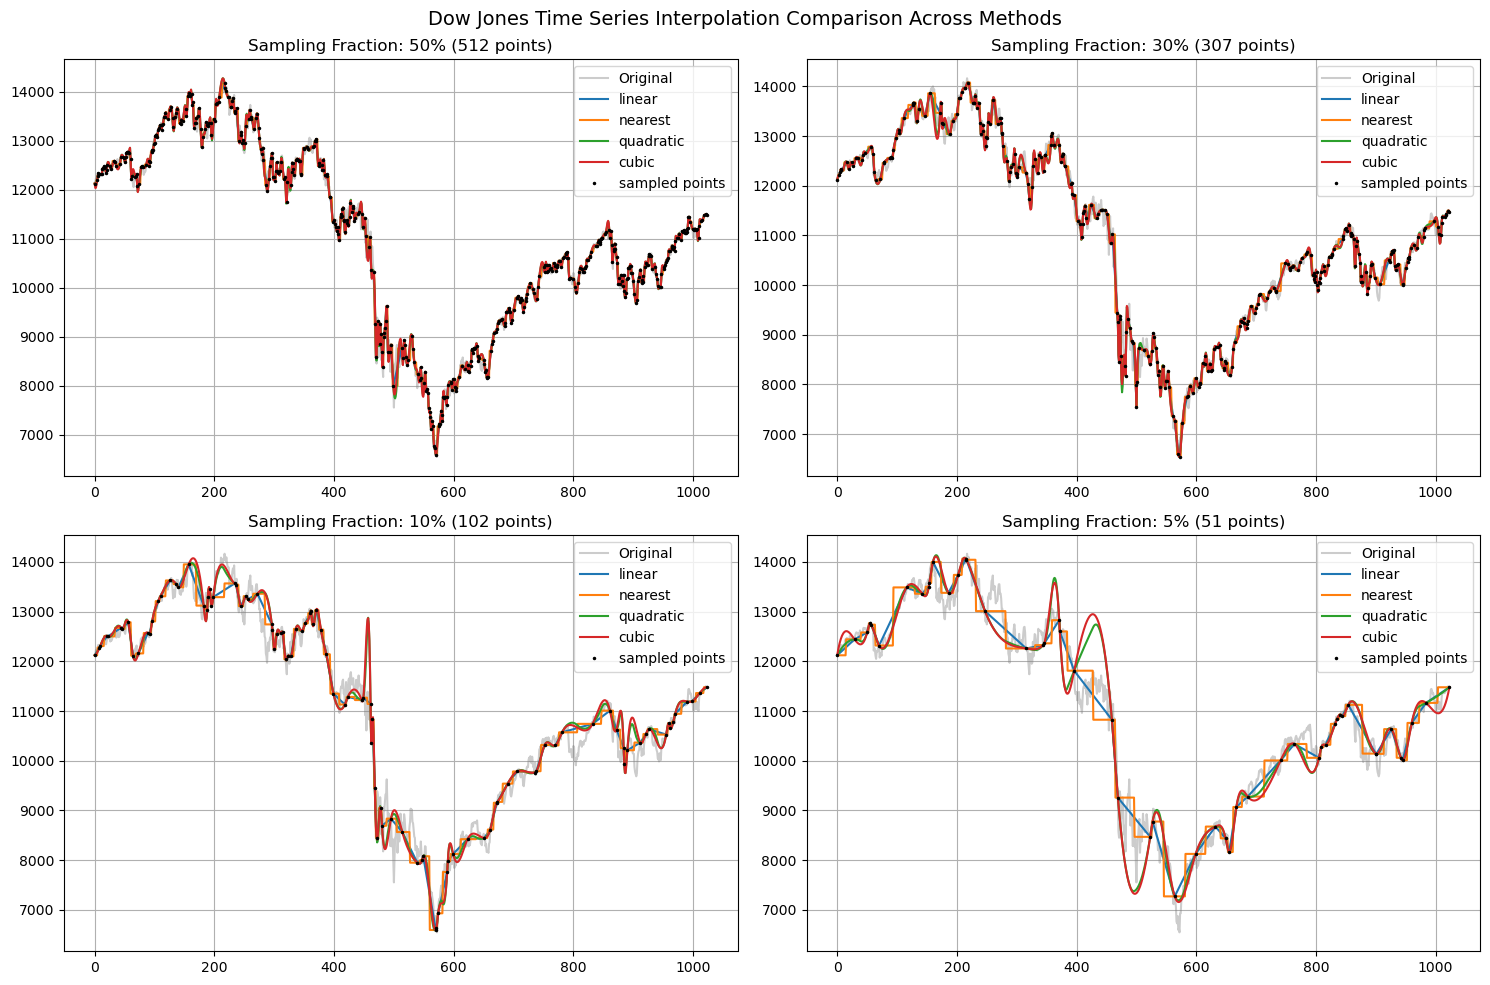

In [29]:
# Load the historical Dow Jones index time series data
data = np.loadtxt("dow.txt")
x_full = np.arange(len(data))
y_full = data

# Define downsampling rates and 1D interpolation methods to compare
fractions =[0.50, 0.30, 0.10, 0.05]
methods = ['linear', 'nearest', 'quadratic', 'cubic']

plt.figure(figsize=(15, 10))

# Iterate over each downsampling fraction to create a 2x2 grid of subplots
for i, frac in enumerate(fractions):
    
    # Randomly select a subset of indices without replacement
    idx = np.sort(rng.choice(len(data), size=int(len(data) * frac), replace=False))
    
    # Anchor the first and last endpoints to prevent out-of-bounds extrapolation errors
    idx[0], idx[-1] = 0, len(data) - 1

    plt.subplot(2, 2, i + 1)

    # Plot original full dataset in background as reference
    plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')

    # Fit each interpolation model on sampled points and reconstruct full series
    for method in methods:
        f_interp = interpolate.interp1d(x_full[idx], y_full[idx], kind=method)
        plt.plot(x_full, f_interp(x_full), label=method)

    # Highlight the sparse sample points used for fitting
    plt.plot(x_full[idx], y_full[idx], 'k.', markersize=3, label='sampled points')
    plt.title(f'Sampling Fraction: {int(frac * 100)}% ({len(idx)} points)')
    plt.grid(True)
    plt.legend()

plt.suptitle('Dow Jones Time Series Interpolation Comparison Across Methods', fontsize=14)
plt.tight_layout()
plt.savefig("dowjones.png")
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

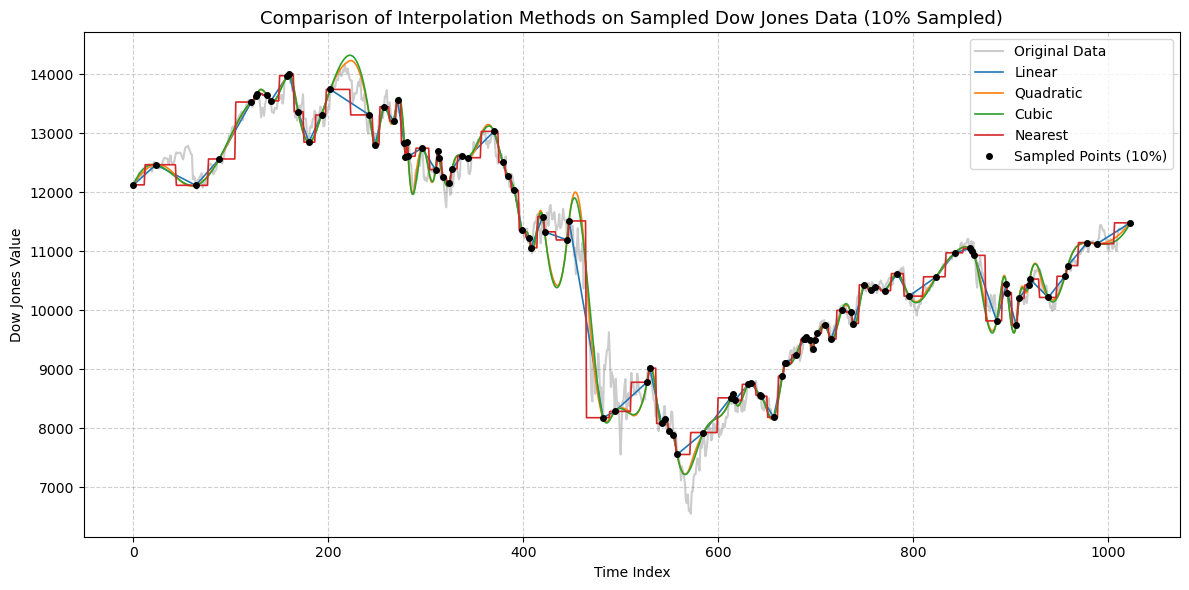

In [30]:
# Randomly select a 10% sample subset without replacement
idx_sample = np.sort(rng.choice(len(data), size=int(len(data) * 0.10), replace=False))

# Anchor first and last points to ensure continuous coverage across the full domain
idx_sample[0], idx_sample[-1] = 0, len(data) - 1

# Extract x and y coordinates corresponding to the sampled subset
sample_x, sample_y = x_full[idx_sample], y_full[idx_sample]

plt.figure(figsize=(12, 6))

# Plot full time series in background as reference baseline
plt.plot(x_full, y_full, color='gray', alpha=0.4, linewidth=1.5, label='Original Data')

# Fit and reconstruct the full series using four distinct 1D interpolation methods
for method in ['linear', 'quadratic', 'cubic', 'nearest']:
    f_interp = interpolate.interp1d(sample_x, sample_y, kind=method)
    plt.plot(x_full, f_interp(x_full), label=method.capitalize(), linewidth=1.2)

# Overlay the 10% sample points used for model fitting
plt.plot(sample_x, sample_y, 'ko', markersize=4, label='Sampled Points (10%)')
plt.title('Comparison of Interpolation Methods on Sampled Dow Jones Data (10% Sampled)', fontsize=13)
plt.xlabel('Time Index')
plt.ylabel('Dow Jones Value')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("singlesampling.png")
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* Using SciPy's interp1d, this script compares linear, nearest, quadratic, and cubic interpolation by reconstructing a sine wave and Dow Jones time series from randomly sampled points. It evaluates performance across multiple sampling densities, anchors the boundary endpoints to prevent out-of-bound errors, and optimizes performance via direct index sampling.